# 20M params LLM

In [114]:
pip install -q jax flax matplotlib tiktoken grain datasets optax orbax gradio

Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.


In [116]:
import jax
import jax.numpy as jnp
import flax.nnx as nnx

import tiktoken # tokenization
from datasets import load_dataset
import grain.python as grain

import optax

import orbax
from orbax import checkpoint
from jax.sharding import SingleDeviceSharding 

import gradio as gr

from pathlib import Path

import matplotlib.pyplot as plt

# Building the LLM Architecture

## Creating the embedding layers

In [14]:
class TokenAndPositionEmbedding(nnx.Module):
    def __init__(self, maxlen, vocab_size, embed_dim, *, rngs):
        self.token_emb = nnx.Embed(vocab_size, embed_dim, rngs=rngs) # (vocab_size, D)
        self.pos_emb = nnx.Embed(maxlen, embed_dim, rngs=rngs) # (maxlen, D)

    def __call__(self, x):
        seq_len = x.shape[1]
        positions = jnp.arange(seq_len)[None, :] # (1, T, D)
        return self.token_emb(x) + self.pos_emb(positions) # (B, T, D)

## Building the Transformer Block

In [11]:
class TransformerBlock(nnx.Module):

    def __init__(self, embed_dim, num_heads, ff_dim, *, rngs):
        self.attention = nnx.MultiHeadAttention(
            num_heads=num_heads,
            in_features=embed_dim,
            qkv_features=embed_dim,
            out_features=embed_dim,
            decode=False,
            rngs=rngs
        )

    def __call__(self, x, mask=None):
        attn_out = self.attention(x, mask=mask)
        x = x + attn_out
        return x

## Defining the model configuration

In [92]:
class GPT(nnx.Module):

    def __init__(self, maxlen, vocab_size, embed_dim, num_heads, feed_forward_dim, num_transformer_blocks, *, rngs):
        self.maxlen = maxlen
        self.embedding = TokenAndPositionEmbedding(maxlen, vocab_size, embed_dim, rngs=rngs)
        
        self.transformer_blocks = nnx.List([
            TransformerBlock(embed_dim, num_heads, feed_forward_dim, rngs=rngs)
            for _ in range(num_transformer_blocks)
        ])

        self.output_layer = nnx.Linear(embed_dim, vocab_size, use_bias=False, rngs=rngs)

    def causal_attention_mask(self, seq_len):
        return jnp.tril(jnp.ones((seq_len, seq_len)))

    def __call__(self, token_ids):
        seq_len = token_ids.shape[1]
        mask = self.causal_attention_mask(seq_len)
        x = self.embedding(token_ids)

        for block in self.transformer_blocks:
            x = block(x, mask=mask)

        logits = self.output_layer(x)
        return logits

## Defining a model

In [93]:
model = GPT(
    maxlen=128,
    vocab_size=tokenizer.n_vocab,
    embed_dim=192,
    num_heads=6,
    feed_forward_dim=512,
    num_transformer_blocks=6,
    rngs=nnx.Rngs(0)
)

model

GPT( # Param: 20,212,608 (80.9 MB)
  maxlen=128,
  embedding=TokenAndPositionEmbedding( # Param: 9,673,920 (38.7 MB)
    token_emb=Embed( # Param: 9,649,344 (38.6 MB)
      embedding=Param( # 9,649,344 (38.6 MB)
        value=Array(shape=(50257, 192), dtype=dtype('float32'))
      ),
      num_embeddings=50257,
      features=192,
      dtype=dtype('float32'),
      param_dtype=float32,
      promote_dtype=<function promote_dtype at 0x000001C03E4B2D40>
    ),
    pos_emb=Embed( # Param: 24,576 (98.3 KB)
      embedding=Param( # 24,576 (98.3 KB)
        value=Array(shape=(128, 192), dtype=dtype('float32'))
      ),
      num_embeddings=128,
      features=192,
      dtype=dtype('float32'),
      param_dtype=float32,
      promote_dtype=<function promote_dtype at 0x000001C03E4B2D40>
    )
  ),
  transformer_blocks=List([
    TransformerBlock( # Param: 148,224 (592.9 KB)
      attention=MultiHeadAttention( # Param: 148,224 (592.9 KB)
        num_heads=6,
        in_features=192,
        q

# Loading and processing the data

## Importing our dataset

In [ ]:
ds = load_dataset("roneneldan/TinyStories")

## Choosing a tokenizer

In [20]:
tokenizer = tiktoken.get_encoding("gpt2")

## Defining a dataset class

In [66]:
class StoryDataset:
    
    def __init__(self, stories, maxlen, tokenizer):
        self.stories = stories
        self.maxlen = maxlen
        self.tokenizer = tokenizer
        self.end_token = tokenizer.encode('<|endoftext|>', \
            allowed_special={'<|endoftext|>'})[0]

    def __len__(self):
        return len(self.stories)

    def __getitem__(self, idx):
        story = self.stories[idx]
        tokens = self.tokenizer.encode(story, allowed_special={'<|endoftext|>'})

        if len(tokens) > self.maxlen:
            tokens = tokens[:self.maxlen]

        tokens.extend([0] * (self.maxlen - len(tokens)))
        return tokens

## Building a data loader

In [62]:
def create_dataloader(
    stories,
    tokenizer,
    maxlen,
    batch_size,
    shuffle=False,
    num_epochs=1,
    seed=42,
    worker_count=0
):
    dataset = StoryDataset(stories, maxlen, tokenizer)
    estimated_batches = len(dataset) // batch_size

    sampler = grain.IndexSampler(
        num_records = len(dataset),
        shuffle=shuffle,
        seed=seed,
        shard_options=grain.NoSharding(),
        num_epochs=num_epochs
    )

    dataloader = grain.DataLoader(
        data_source=dataset,
        sampler=sampler,
        operations=[grain.Batch(batch_size=batch_size, drop_remainder=True)],
        worker_count=worker_count
    )

    return dataloader, estimated_batches

## Defining a dataloader

In [84]:
stories = ds["train"]["text"]

dataloader, batches_per_epoch = create_dataloader(
    stories=stories,
    tokenizer=tokenizer,
    maxlen=128,
    batch_size=32,
    shuffle=False,
    num_epochs=1,
    seed=42,
    worker_count=0
)

# Training the model

In [78]:
def loss_fn(model, batch):
    inputs, targets = batch
    logits = model(inputs)
    loss = optax.softmax_cross_entropy_with_integer_labels(logits, targets).mean()
    return loss, logits

In [79]:
num_epochs = 3
total_steps = batches_per_epoch * num_epochs
warmup_steps = max(1, total_steps // 10)
print(f"Total training steps : {total_steps:,}")
print(f"Warmup steps : {warmup_steps:,}")

Total training steps : 198,723
Warmup steps : 19,872


In [80]:
lr_schedule = optax.warmup_cosine_decay_schedule(
    init_value=0.0,
    peak_value=3e-4,
    warmup_steps=warmup_steps,
    decay_steps=total_steps,
    end_value=1e-5
)

## Using an optimizer from optax

In [82]:
optimizer = nnx.ModelAndOptimizer(
    model,
    optax.adamw(learning_rate=lr_schedule, weight_decay=0.01)
)

metrics = nnx.MultiMetric(loss=nnx.metrics.Average('loss'))

## Defining and JIT-compiling the training step


In [85]:
@nnx.jit
def train_step(model, optimizer, metrics, batch):
    grad_fn = nnx.value_and_grad(loss_fn, has_aux=True)
    (loss, logits), grads = grad_fn(model, batch)

    metrics.update(loss=loss, logits=logits, labels=batch[1])
    optimizer.update(grads)

## Training the model

In [94]:
metrics_history = {'train_loss': []}

prep_target_batch = jax.vmap(lambda tokens: jnp.concatenate((tokens[1:], jnp.array([0]))))

for epoch in range(num_epochs):
    step = 0
    for batch in dataloader:
        input_batch = jnp.array(jnp.array(batch).T).astype(jnp.int32)
        target_batch = prep_target_batch(
            jnp.array(jnp.array(batch).T)).astype(jnp.int32)
        print(".", end="")
        train_step(model, optimizer, metrics, (input_batch, target_batch))

        if (step + 1) % 2 == 0:
            for metric, value in metrics.compute().items():
                metrics_history[f'train_{metric}'].append(value)
            metrics.reset()

            current_lr = lr_schedule(step)
            print(f"\nEpoch: {epoch + 1}, Step {step + 1}, Loss: {metrics_history['train_loss'][-1]:.4f}, "
                  f"LR: {current_lr:.2e}")
        step += 1

..
Epoch: 1, Step 2, Loss: 10.8889, LR: 1.51e-08
..
Epoch: 1, Step 4, Loss: 10.8885, LR: 4.53e-08
..
Epoch: 1, Step 6, Loss: 10.8915, LR: 7.55e-08
..
Epoch: 1, Step 8, Loss: 10.8879, LR: 1.06e-07
..
Epoch: 1, Step 10, Loss: 10.8821, LR: 1.36e-07
..
Epoch: 1, Step 12, Loss: 10.8961, LR: 1.66e-07
..
Epoch: 1, Step 14, Loss: 10.8861, LR: 1.96e-07
..
Epoch: 1, Step 16, Loss: 10.8873, LR: 2.26e-07
..
Epoch: 1, Step 18, Loss: 10.8988, LR: 2.57e-07
..
Epoch: 1, Step 20, Loss: 10.8921, LR: 2.87e-07
..
Epoch: 1, Step 22, Loss: 10.8912, LR: 3.17e-07
..
Epoch: 1, Step 24, Loss: 10.8577, LR: 3.47e-07
..
Epoch: 1, Step 26, Loss: 10.8854, LR: 3.77e-07
..
Epoch: 1, Step 28, Loss: 10.9031, LR: 4.08e-07
..
Epoch: 1, Step 30, Loss: 10.8536, LR: 4.38e-07
..
Epoch: 1, Step 32, Loss: 10.8741, LR: 4.68e-07
..
Epoch: 1, Step 34, Loss: 10.8952, LR: 4.98e-07
..
Epoch: 1, Step 36, Loss: 10.8904, LR: 5.28e-07
..
Epoch: 1, Step 38, Loss: 10.8926, LR: 5.59e-07
..
Epoch: 1, Step 40, Loss: 10.8928, LR: 5.89e-07
..
E

KeyboardInterrupt: 

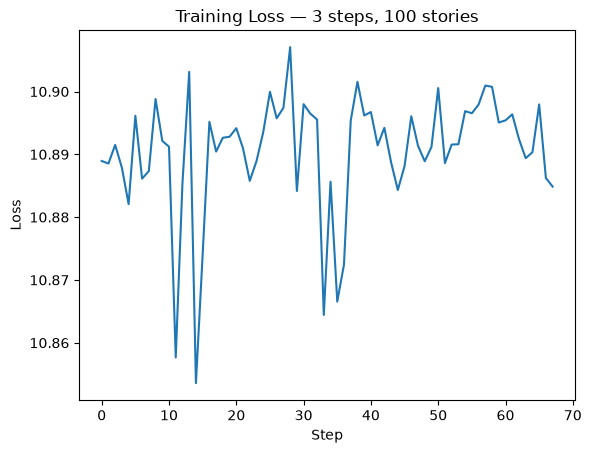

In [95]:
import matplotlib.pyplot as plt
plt.plot(metrics_history['train_loss'])
plt.title('Training Loss — 3 steps, 100 stories')
plt.xlabel('Step')
plt.ylabel('Loss')
plt.show()

# Saving model checkpoints

In [ ]:
checkpoint_path = Path.cwd() / "small_gpt.orbax"

checkpointer = orbax.checkpoint.PyTreeCheckpointer()

checkpointer.save(checkpoint_path, nnx.state(model), force=True)
print(f"Model saved as {checkpoint_path}")

# Load model

In [103]:
cpu_device = jax.devices('cpu')[0]
cpu_sharding = SingleDeviceSharding(cpu_device)

In [104]:
restore_args = jax.tree_util.tree_map(
    lambda _: checkpoint.ArrayRestoreArgs(sharding=cpu_sharding),
    nnx.state(model)
)

In [106]:
checkpoint_path = Path.cwd() / "small_checkpoint.orbax"
checkpointer = orbax.checkpoint.PyTreeCheckpointer()

In [107]:
restored_state = checkpointer.restore(
    checkpoint_path,
    item=nnx.state(model),
    restore_args=restore_args)

nnx.update(model,restored_state)

# Running inference

In [112]:
def create_story(prompt: str, temperature: float = 1.0, max_new_tokens: int = 50):
    end_token = tokenizer.encode(
        "<|endoftext|>",
        allowed_special={"<|endoftext|>"},
    )[0]

    tokens = tokenizer.encode(prompt)
    key = jax.random.key(0)

    for _ in range(max_new_tokens):
        x = jnp.array(tokens[-model.maxlen :])[None, :]  # (1, T)

        logits = model(x)[0, -1, :]  # logits

        logits = logits / temperature
        key, subkey = jax.random.split(key)
        next_token = int(jax.random.categorical(subkey, logits))

        tokens.append(next_token)
        if next_token == end_token:
            break

    return tokenizer.decode(tokens)

In [111]:
create_story("Once upon a time a big bear ", 0.2, 30)

'Once upon a time a big bear  Porter 415 Abramaked RainbowAtlantic Usage Vulcan demolition03 Surface Alexandragov (?, client (~ enlarg absence BravAmidicultyBearirmation SAL employed naval regional Acid clinic Realms'

# Interactive chat demo

In [117]:
demo = gr.Interface(
    fn=create_story,
    inputs=[
        gr.Textbox(label="Story Prompt"),         
        gr.Slider(
            minimum=0, maximum=1.0, value=0.8, step=0.01, label="Temperature"
        ),
        gr.Slider(minimum=0, maximum=200, value=10, step=1, label="Max Tokens"
        )
    ],
    outputs=["text"]
)

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/20 13:52:56 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: i/o timeout


Created dataset file at: .gradio\flagged\dataset1.csv


needs to train a full model and deploy it to huggingface